Predikce hodinové spotřeby elektřiny jedné domácnosti na základě času, předchozí spotřeby a venkovní teploty s využitím datasetu "Individual Household Electric Power Consumption in Sceaux, Paris"

## 1. Introduction

The goal is to predict the energy consumed by one household during a one-hour interval, in kWh. 

- The **Main Model** uses outside temperature, hour of day, day of week, and consumption exactly 24 hours earlier as inputs.
- The **Reduced Model** is a comparison variant without lagged consumption.

| Method | Inputs / prediction rule |
| --- | --- |
| Main Model | Temperature, hour, day of week, 24-hour consumption lag |
| Reduced Model | Temperature, hour, day of week |
| Mean baseline | Mean consumption in the training set |
| 24-hour persistence | Consumption exactly 24 hours earlier |

**Requirements:**
1. Installing `ucimlrepo`, `numpy`, `pandas`, `matplotlib`, and `scikit-learn` via pip.
2. Placing both temperature CSV files in `data/` (sceaux_hourly_temperature.csv, sceaux_temperature_metadata.csv).

**Solution specifics**:
1. Temperature dataset contains historic actual temperature, not the temperature forecast.
2. Household consumption dataset does not mention timezone in the data source. UTC timezone is assumed, which can influence the outputs as the consumption data is merged with temperature with UTC. Therefore the timezone alignment between the consumption and temperature is an assumption.


## 2. Setup and helper functions


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

DATA = Path("data")
assert (DATA / "sceaux_hourly_temperature.csv").is_file(), "Temperature file not loaded"

TARGET = "Global_active_power"

In [3]:
# helpers
def audit(frame, unique_features):
    display(frame.head())
    print("Size:", frame.shape)
    display(pd.DataFrame({"type": frame.dtypes, "missing": frame.isna().sum()}))
    print("Exact duplicates:", frame.duplicated().sum())
    
    for feature in unique_features:
        assert frame[feature].is_unique, print("Duplicated:", frame[feature].duplicated().sum())
    print("Verified unique features:", unique_features)

def audit_complete_frame(frame, features, target):    
    assert frame[features + [target]].notna().all().all()
    assert np.isfinite(frame[features + [target]].to_numpy(dtype=float)).all()

def scores(y, prediction):
    return {"MAE [kWh]": mean_absolute_error(y, prediction),
            "RMSE [kWh]": root_mean_squared_error(y, prediction)}

In [ ]:
temperature = "temperature"
lag = "consumption_lag_24h"
hour = "hour"
day_of_week = "day_of_week"

FEATURES_REDUCED = [temperature, hour, day_of_week]
FEATURES_MAIN = [temperature, hour, day_of_week, lag]

## 3. Data sources and preparation


Requires installing `ucimlrepo`, `numpy`, `pandas`, `matplotlib`, and `scikit-learn`, and placing both temperature CSV files in `data/`. The electricity dataset is fetched from UCI.

### 3.1. Data sources


**Household consumption** measurements of electric power consumption in one household with a one-minute sampling rate in Sceaux (7km of Paris, France) between December 2006 and November 2010 (47 months).
Requires `pip install ucimlrepo`

Source: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

In [5]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
dataset = fetch_ucirepo(id=235) 
  
# data (as pandas dataframes) 
df_consumption = dataset.data.original.replace(["", "?"], pd.NA)
print(df_consumption.head())


/Users/angelina/UHK/Masters Study/UHK2_Sem3/SU/ukol1/.venv/lib/python3.14/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2: Global_active_power, 3: Global_reactive_power, 4: Voltage, 5: Global_intensity, 6: Sub_metering_1, 7: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  


**Temperature dataset** is downloaded from Open Meteo with per-hour historic temperature from the area of Sceaux. 
- latitude 48.7764, longitude 2.2903
- weather model ERA5-Land
- from 01.12.2006 until 30.11.2010
- timezone UTC

Data source: https://open-meteo.com/en/docs/historical-weather-api?utm_source=chatgpt.com&bounding_box=-90,-180,90,180

In [6]:
df_temperature_metadata = pd.read_csv(DATA / "sceaux_temperature_metadata.csv")
print(df_temperature_metadata.head())

df_temperature = pd.read_csv(DATA / "sceaux_hourly_temperature.csv")
print(df_temperature.head())

    latitude  longitude  elevation  utc_offset_seconds timezone  \
0  48.800003   2.300003       94.0                   0      GMT   

  timezone_abbreviation  
0                   GMT  
               time  temperature_2m (°C)
0  2006-12-01T00:00                  6.5
1  2006-12-01T01:00                  6.1
2  2006-12-01T02:00                  5.9
3  2006-12-01T03:00                  5.7
4  2006-12-01T04:00                  5.4


### 3.2. Basic audit of datasets


In [7]:
audit(df_temperature, ["time"])

,time,temperature_2m (°C)
0,2006-12-01T00:00,6.5
1,2006-12-01T01:00,6.1
2,2006-12-01T02:00,5.9
3,2006-12-01T03:00,5.7
4,2006-12-01T04:00,5.4


Size: (35064, 2)


,type,missing
time,str,0
temperature_2m (°C),float64,0


Exact duplicates: 0
Verified unique features: ['time']


In [8]:
audit(df_consumption, [])

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


Size: (2075259, 9)


,type,missing
Date,str,0
Time,str,0
Global_active_power,object,25979
Global_reactive_power,object,25979
Voltage,object,25979
Global_intensity,object,25979
Sub_metering_1,object,25979
Sub_metering_2,object,25979
Sub_metering_3,float64,25979


Exact duplicates: 0
Verified unique features: []


Output:
* **Temperature dataset** 
    * contains no duplicates and missing values
    * temperature is numeric; time is converted from a string to datetime before merging
    * time is verified to be unique across the whole dataset
    * UTC timezone (from metadata)
* **Consumption dataset** 
    * contains no duplicates
    * points of interest are 'Global_active_power', 'Date' and 'Time', other features may be dropped
    * 'Global_active_power' has 25979 missing values
    * 'Global_active_power' and other measurements are of type object, requires the transformation to float
    * the measurements are per minute, while the temperature data is per hour
    * transformation to the kWh will be applied on 'Global_active_power', along with the handling of missing values.
    * 'Date' and 'Time' columns will be merged to map to 'time' form temperature dataset after the transformation to per-hour measurements
    * NOTE: the timezone is not clear from the datasource, therefore UTC is assumed

### 3.3. Household consumption preprocessing


1. limit only to 'Date', 'Time' and 'Global_active_power'
2. transform the 'Global_active_power' from object to float64
3. merge 'Date' and 'Time' columns into one in format similar to 'time' from temeprature data "yyyy-mm-dd hh:mm" as a start hour of a one-hour timestamp
4. transform the per-minute time series to per-hour 
    - SUM(Global_active_power in 60 minutes per hour) / 60 = average Global_active_power in an hour
    - before that, check how many missing values in scope of one hour
        - set a threshold 't' for acceptable missing measurements  
        - count valid measurements for each hour
        - keep hours with maximum of 't' missing measurements
        - if hour has more than 't' missing measurements, mark the whole hour as NA

In [9]:
# 1. Limit only to 'Date', 'Time' and 'Global_active_power'.
# Consumption dataset contains additional fields, 
# but the point of interest is `Global_active_power`, so other columns will be dropped.
df_consumption_target = df_consumption[["Date", "Time", "Global_active_power"]].copy()
print(df_consumption_target.head())

         Date      Time Global_active_power
0  16/12/2006  17:24:00               4.216
1  16/12/2006  17:25:00               5.360
2  16/12/2006  17:26:00               5.374
3  16/12/2006  17:27:00               5.388
4  16/12/2006  17:28:00               3.666


In [10]:
# 2. transform the 'Global_active_power' from object to float64
numeric_cols = ["Global_active_power"]

df_consumption_target[numeric_cols] = (
    df_consumption_target[numeric_cols]
    .apply(pd.to_numeric, errors="coerce")
    .astype("float64")
)

print(df_consumption_target.dtypes)

Date                       str
Time                       str
Global_active_power    float64
dtype: object


In [11]:
# 3. Merge Date and Time into the start of each one-hour interval.
df_consumption_target_time = df_consumption_target.copy()
df_consumption_target_time["time"] = (
    pd.to_datetime(
        df_consumption_target["Date"] + " " + df_consumption_target["Time"],
        format="%d/%m/%Y %H:%M:%S",
    )
    .dt.floor("h")
)
df_consumption_target_time = df_consumption_target_time.drop(columns=["Date", "Time"])

print(df_consumption_target_time.head())
print(df_consumption_target_time.dtypes)

   Global_active_power                time
0                4.216 2006-12-16 17:00:00
1                5.360 2006-12-16 17:00:00
2                5.374 2006-12-16 17:00:00
3                5.388 2006-12-16 17:00:00
4                3.666 2006-12-16 17:00:00
Global_active_power           float64
time                   datetime64[us]
dtype: object


In [12]:
# Transform
df_consumption_transformed = None

# Count valid and missing measurements for each hour before transformation.
# size counts all rows, count takes only non-missing
hourly_measurement_counts = (
    df_consumption_target_time.groupby("time")["Global_active_power"]
    .agg(total_values="size", valid_values="count")
)
hourly_measurement_counts["missing_values"] = (
    hourly_measurement_counts["total_values"]
    - hourly_measurement_counts["valid_values"]
)

# Display hours containing at least one missing measurement.
display(
    hourly_measurement_counts.loc[
        hourly_measurement_counts["missing_values"] > 0,
        ["valid_values", "missing_values"],
    ].reset_index()
)

,time,valid_values,missing_values
0,2006-12-21 11:00:00,58,2
1,2006-12-30 10:00:00,58,2
2,2007-01-14 18:00:00,59,1
3,2007-01-28 17:00:00,59,1
4,2007-02-22 22:00:00,58,2
...,...,...,...
497,2010-09-28 16:00:00,0,60
498,2010-09-28 17:00:00,0,60
499,2010-09-28 18:00:00,0,60
500,2010-09-28 19:00:00,47,13


Missing values: some hours miss only 1-2 values, some have no valid value. 

- Target consumption missing: exclude in all cases
- Consumption 24 hours earlier is missing: excluded if previous consumption is a feature

Aggregate to hourly consumption. 
- Calculate as mean value in case there is a maximum of 't' missing measurements. 
    - 't' is set to 5 as a simple guess, not verified to be the optimal value
- Otherwise, set hourly consumption to NaN. Preserve a regular hourly timeline, including those NaN hours.

In [ ]:
# 1. Aggregate hours to energy consumption in kWh.
t = 5  # threshold = Maximum allowed missing minute measurements per hour
min_valid_measurements = 60 - t

minute_consumption = df_consumption_target_time.assign(
    time=pd.to_datetime(
        df_consumption_target_time["time"],
        format="%Y-%m-%dT%H:%M"
    )
).set_index("time")["Global_active_power"]

# Resampling also inserts absent hours, preserving the hourly timeline.
hourly_consumption = minute_consumption.resample("h")
valid_measurements = hourly_consumption.count()

# Estimate hourly energy using the mean of available minute measurements.
df_consumption_transformed = (
    hourly_consumption.mean()
    .where(valid_measurements >= min_valid_measurements)
    .rename("Global_active_power")
    .reset_index()
)

df_consumption_transformed["time"] = (
    df_consumption_transformed["time"].dt.strftime("%Y-%m-%dT%H:%M")
)

df_consumption_hourly = df_consumption_transformed.copy()

# Hours with more than t missing measurements must have missing consumption.
assert df_consumption_hourly["Global_active_power"].isna().to_numpy()[
    valid_measurements.lt(min_valid_measurements).to_numpy()
].all()

display(df_consumption_hourly.head())

,time,Global_active_power
0,2006-12-16T17:00,NaN
1,2006-12-16T18:00,3.632200
2,2006-12-16T19:00,3.400233
3,2006-12-16T20:00,3.268567
4,2006-12-16T21:00,3.056467


Create yesterday’s consumption feature: consumption exactly 24 hours earlier.

In [14]:
df_consumption_master = df_consumption_hourly.copy()

# dataframe has one row for every consecutive hour
# If consumption at t - 24 hours is NaN, the lag at t is also NaN.
df_consumption_master["consumption_lag_24h"] = (
    df_consumption_master["Global_active_power"].shift(24)
)

print(df_consumption_master.head())

               time  Global_active_power  consumption_lag_24h
0  2006-12-16T17:00                  NaN                  NaN
1  2006-12-16T18:00             3.632200                  NaN
2  2006-12-16T19:00             3.400233                  NaN
3  2006-12-16T20:00             3.268567                  NaN
4  2006-12-16T21:00             3.056467                  NaN


The original `Global_active_power` measurements are power in kW. Getting the average of per-minute power foe each hour (with the threshold of maximum missing values allowed) produces hourly energy in kWh. The existing column name is retained in the code, but all subsequent targets, lag values, predictions, and errors refer to hourly energy in kWh.

### 3.4. Merge datasets


#### Data range check

In [15]:
# Date range comparison
print("Temperature time range:", df_temperature.time.min(), "-", df_temperature.time.max())
print("Consumption time range:", df_consumption_master.time.min(), "-", df_consumption_master.time.max())

Temperature time range: 2006-12-01T00:00 - 2010-11-30T23:00
Consumption time range: 2006-12-16T17:00 - 2010-11-26T21:00


Temperature: 1.12.2006 - 30.11.2010

Consumption: 16.12.2006 - 26.11.2010

#### Merge

In [16]:
# Keep every consumption hour and match its temperature by time.

df_master = df_consumption_master.assign(
    time=pd.to_datetime(df_consumption_master["time"])
).merge(
    df_temperature.rename(columns={"temperature_2m (°C)": "temperature"}).assign(
        time=pd.to_datetime(df_temperature["time"])
    )[["time", "temperature"]],
    on="time",
    how="left",
    validate="one_to_one",
)

audit(df_master, ["time"])

,time,Global_active_power,consumption_lag_24h,temperature
0,2006-12-16 17:00:00,NaN,NaN,6.4
1,2006-12-16 18:00:00,3.632200,NaN,6.2
2,2006-12-16 19:00:00,3.400233,NaN,5.9
3,2006-12-16 20:00:00,3.268567,NaN,5.1
4,2006-12-16 21:00:00,3.056467,NaN,4.3


Size: (34589, 4)


,type,missing
time,datetime64[us],0
Global_active_power,float64,447
consumption_lag_24h,float64,470
temperature,float64,0


Exact duplicates: 0
Verified unique features: ['time']


### 3.5. Calendar features and valid observations


In [17]:
# add separate columns 'hour' and 'day of week'
df_master["hour"] = df_master["time"].dt.hour
df_master["day_of_week"] = df_master["time"].dt.dayofweek # Monday = 0, Sunday = 6

In [18]:
# All methods use the same complete measurements for a fair comparison.
# The Reduced Model uses fewer columns, but the same training and evaluation hours.
df_model = df_master.dropna(subset=[TARGET] + FEATURES_MAIN).copy()


## 4. Train, Val, Test split

Chronolohical split is used: earliest 70% for training, next 15% for validation, and last 15% for the final test. 
Incomplete observations are excluded within those periods, so the final row counts may not be exactly 70/15/15.
Chronological splitting is used as the dataset is a time series. It also ensures the model is trained on past observations and evaluated on future observations, along with preventing the model from learning from future observations.

Scalers and learned models are fitted on training data only. Validation supports development, test results are used only after the specification is fixed. 

MAE measures average absolute error and RMSE gives more weight to large errors, both are reported in kWh.

The target is not standardized. Actual temperature for the target hour is used in this retrospective experiment. Real prediction would need temperature information available at prediction time, such as a weather forecast. Lagged consumption is assumed to have been observed before prediction.

In [19]:
# Define boundaries on the complete chronological timeline, before dropping NaNs.
timeline = df_master["time"].sort_values().reset_index(drop=True)
train_end = timeline.iloc[int(len(timeline) * 0.70)]
val_end = timeline.iloc[int(len(timeline) * 0.85)]

def split_by_time(df):
    df = df.sort_values("time")
    train = df.loc[df["time"] < train_end].copy()
    val = df.loc[(df["time"] >= train_end) & (df["time"] < val_end)].copy()
    test = df.loc[df["time"] >= val_end].copy()
    return train, val, test

train, val, test = split_by_time(df_model)
print("Train:", len(train), "Validation:", len(val), "Test:", len(test))
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    audit_complete_frame(part, FEATURES_MAIN, TARGET)
    assert part.time.is_unique
    print(name, "period:", part.time.min(), "to", part.time.max())
sets = [set(part.time) for part in [train, val, test]]
assert all(sets[i].isdisjoint(sets[j]) for i in range(3) for j in range(i + 1, 3))
assert len(set.union(*sets)) == len(df_model)
assert train.time.max() < val.time.min()
assert val.time.max() < test.time.min()

y_train = train[TARGET]
y_val = val[TARGET]
y_test = test[TARGET]


Train: 23962 Validation: 5052 Test: 4931
Train period: 2006-12-17 18:00:00 to 2009-09-20 12:00:00
Validation period: 2009-09-20 13:00:00 to 2010-04-24 16:00:00
Test period: 2010-04-24 17:00:00 to 2010-11-26 20:00:00


## 5. EDA

### Descriptive statistics and feature distributions

,temperature,hour,day_of_week,consumption_lag_24h,Global_active_power
count,23962.000000,23962.000000,23962.000000,23962.000000,23962.000000
mean,11.368684,11.501043,2.996494,1.086400,1.086250
std,6.851076,6.927638,1.995275,0.928561,0.928592
min,-10.400000,0.000000,0.000000,0.124000,0.124000
25%,6.400000,5.000000,1.000000,0.322808,0.323108
50%,11.400000,12.000000,3.000000,0.764900,0.764867
75%,16.400000,18.000000,5.000000,1.577633,1.576783
max,34.800000,23.000000,6.000000,6.560533,6.560533


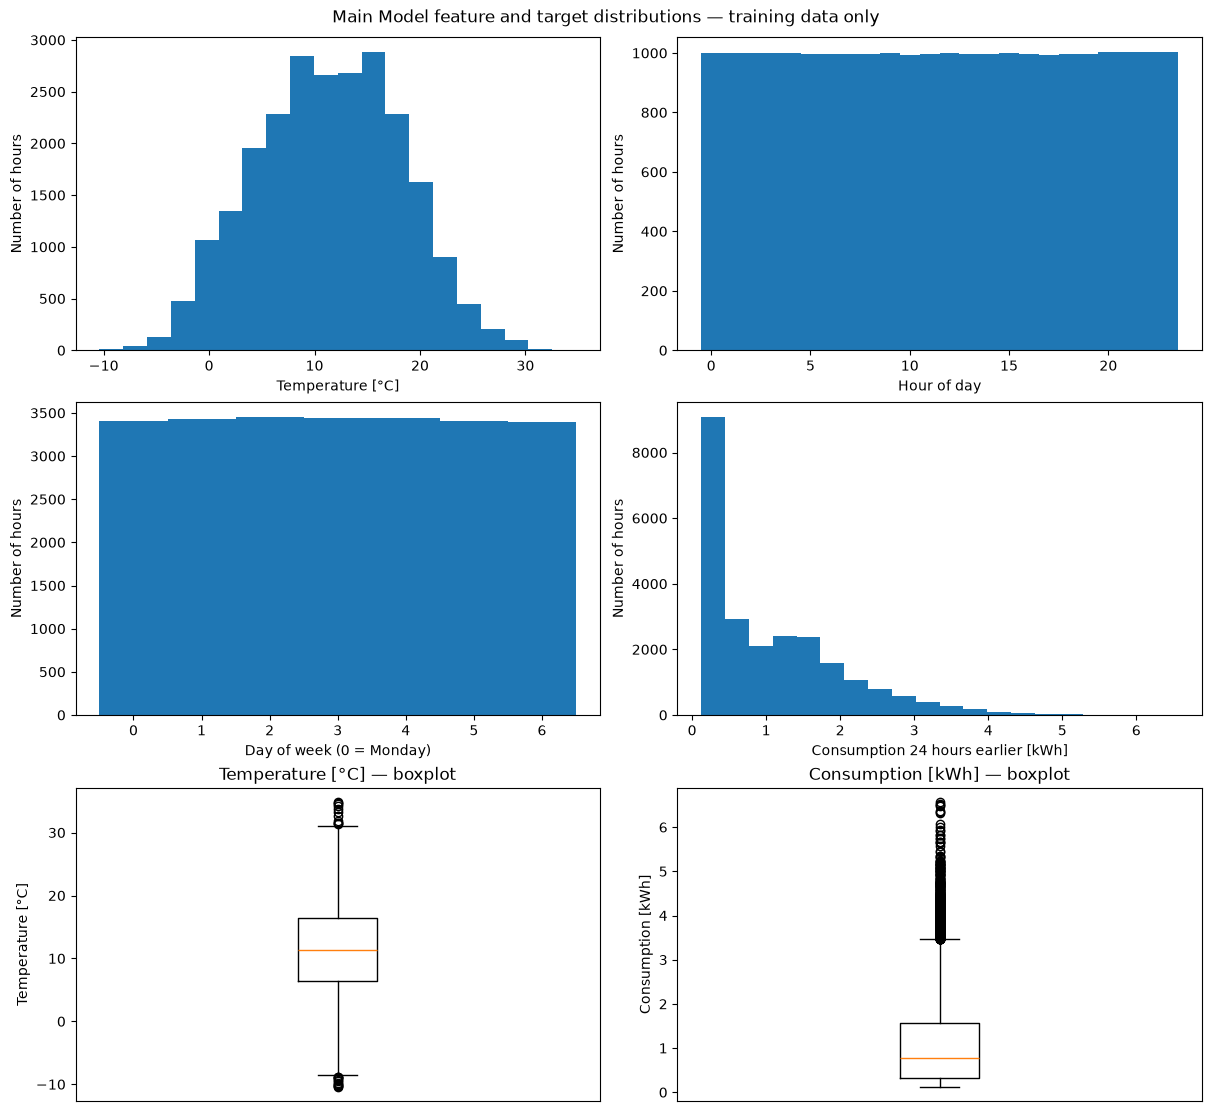

In [20]:
# Explore Main Model features using training data only.
labels_main = ["Temperature [°C]", "Hour of day", "Day of week (0 = Monday)",
            "Consumption 24 hours earlier [kWh]"]
target_label_main = "Consumption [kWh]"
display(train[FEATURES_MAIN + [TARGET]].describe())

fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
for ax, column, label in zip(axes.flat[:4], FEATURES_MAIN, labels_main):
# Center calendar bins on their integer values.
    bins = (np.arange(25) - 0.5 if column == hour else
            np.arange(8) - 0.5 if column == day_of_week else 20)
    ax.hist(train[column], bins=bins)
    ax.set(xlabel=label, ylabel="Number of hours")
if column == hour:
        ax.set_xticks(range(0, 24, 3))
elif column == day_of_week:
        ax.set_xticks(range(7))

for ax, column, label in [
    (axes[2, 0], temperature, labels_main[0]),
    (axes[2, 1], TARGET, target_label_main),
]:
    ax.boxplot(train[column].dropna())
    ax.set(ylabel=label, title=f"{label} — boxplot")
    ax.set_xticks([])

fig.suptitle("Main Model feature and target distributions — training data only")
plt.show()

Consumption descriptive statistics and boxplot show that most values are relatively low, with median under 1., while a long upper tail produces many high values flagged as outliers by the boxplot.

Temperature has a roughly bell-shaped distribution.

### Model features and target relation

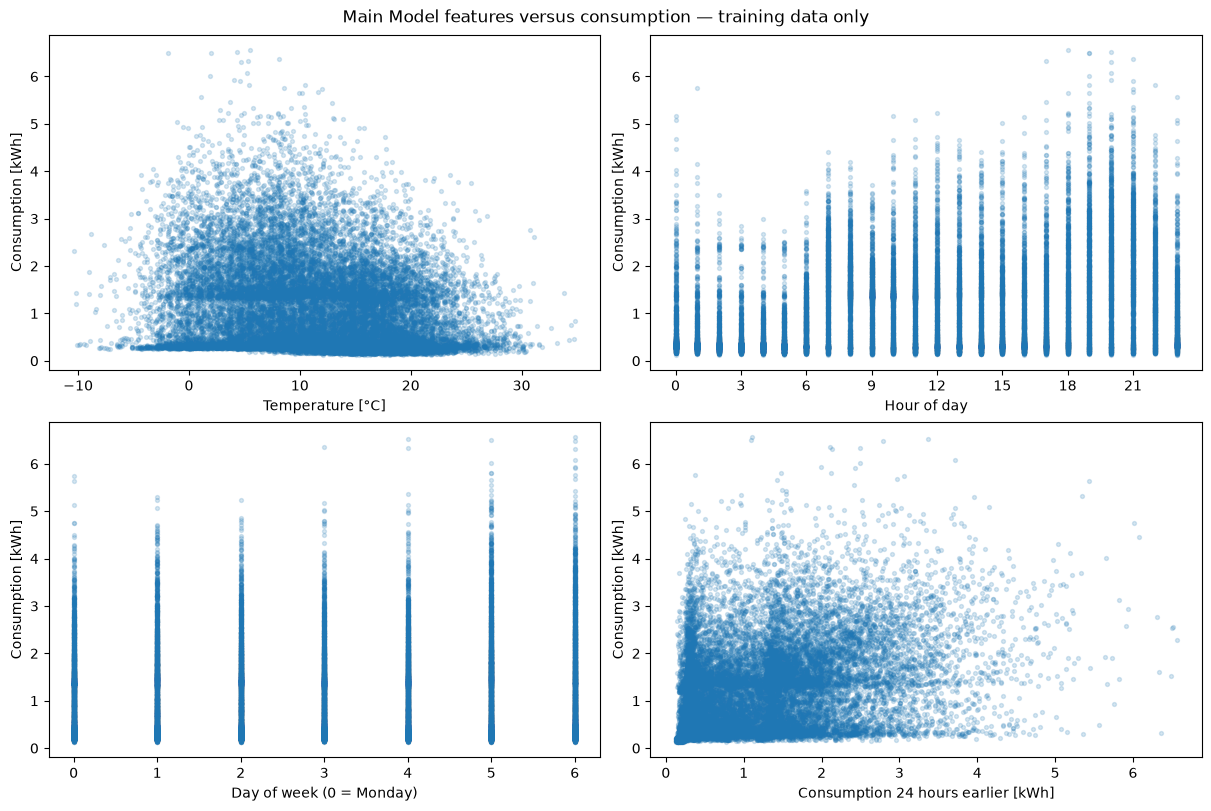

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, column, label in zip(axes.flat, FEATURES_MAIN, labels_main):
    ax.scatter(train[column], train[TARGET], alpha=.18, s=8)
    ax.set(xlabel=label, ylabel=target_label_main)
    if column == hour:
        ax.set_xticks(range(0, 24, 3))
    elif column == day_of_week:
        ax.set_xticks(range(7))
fig.suptitle("Main Model features versus consumption — training data only")
plt.show()

### Correlation matrix

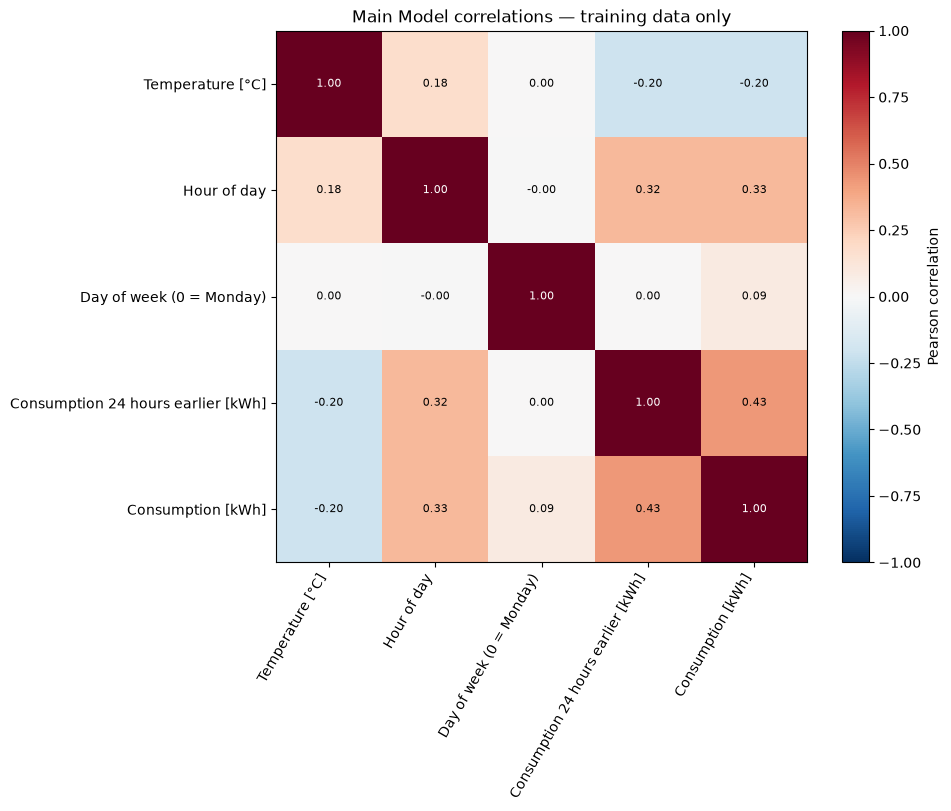

In [22]:
# Pearson correlation measures linear association, not causation.
# Numeric calendar values may hide cyclic relationships.
correlation_main = train[FEATURES_MAIN + [TARGET]].corr()
correlation_labels_main = labels_main + [target_label_main]
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
chart = ax.imshow(correlation_main, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(correlation_main)), correlation_labels_main, rotation=60, ha="right")
ax.set_yticks(range(len(correlation_main)), correlation_labels_main)
for i in range(len(correlation_main)):
    for j in range(len(correlation_main)):
        value = correlation_main.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .5 else "black")
fig.colorbar(chart, ax=ax, label="Pearson correlation")
ax.set_title("Main Model correlations — training data only")
plt.show()

Features ordered by correlation with cosumption: 
- consumption 24h earlier
- hour of day
- temperature
- day of week

Day of week has very low Pearson correlation with consumption. Based on starting setting, it is retained in both models for the comparison as a part of an experiment.


## 6. Main Model: training and validation

The Main Model is a multiple linear regression using temperature, hour, day of week, and consumption exactly 24 hours earlier. 

### 6.1. Scaling

In [23]:
# Fit the scaler on training features only to avoid data leakage.
scaler_main = StandardScaler()
scaler_main.fit(train[FEATURES_MAIN])

# Save the fitted parameters for later checks that the scaler stays unchanged.
scaler_main_snapshot = (
    scaler_main.mean_.copy(),
    scaler_main.scale_.copy(),
    int(scaler_main.n_samples_seen_),
)

z_train_main = pd.DataFrame(
    scaler_main.transform(train[FEATURES_MAIN]),
    columns=FEATURES_MAIN,
    index=train.index,
)
z_val_main = pd.DataFrame(
    scaler_main.transform(val[FEATURES_MAIN]),
    columns=FEATURES_MAIN,
    index=val.index,
)

# Transform test features only in the final test evaluation cell.
display(train[FEATURES_MAIN].head())
display(z_train_main.head())
display(z_train_main.agg(["mean", lambda col: col.std(ddof=0)]))

y_train = train[TARGET]
y_val = val[TARGET]


,temperature,hour,day_of_week,consumption_lag_24h
25,4.7,18,6,3.632200
26,4.7,19,6,3.400233
27,4.2,20,6,3.268567
28,3.7,21,6,3.056467
29,3.5,22,6,2.200133


,temperature,hour,day_of_week,consumption_lag_24h
25,-0.973398,0.938140,1.50534,2.741719
26,-0.973398,1.082492,1.50534,2.491901
27,-1.046381,1.226844,1.50534,2.350102
28,-1.119363,1.371197,1.50534,2.121679
29,-1.148556,1.515549,1.50534,1.199444


,temperature,hour,day_of_week,consumption_lag_24h
mean,-1.708007e-16,6.408733e-17,1.057126e-16,-7.591142e-17
<lambda>,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


### 6.2. Training and validation evaluation


In [24]:
# Fit the Main Model on training data only.
model_main = LinearRegression()
model_main.fit(z_train_main, y_train)

pred_train_main = model_main.predict(z_train_main)
pred_val_main = model_main.predict(z_val_main)

# store for future comparison
main_development_results = pd.DataFrame([
    {"Split": "Train", **scores(y_train, pred_train_main)},
    {"Split": "Validation", **scores(y_val, pred_val_main)},
]).set_index("Split")

display(scores(y_train, pred_train_main))


{'MAE [kWh]': 0.604502037516261, 'RMSE [kWh]': 0.7963742263843786}

## 7. Comparison methods and validation comparison

### 7.1. Reduced Model

This model uses the same linear regression method and the same training hours as the Main Model, but excludes the 24-hour lag. Its scaler is also fitted only on training observations.


In [25]:
# Fit the scaler on training features only to avoid data leakage.
scaler_reduced = StandardScaler()
scaler_reduced.fit(train[FEATURES_REDUCED])

# Save the fitted parameters for later checks that the scaler stays unchanged.
scaler_reduced_snapshot = (
    scaler_reduced.mean_.copy(),
    scaler_reduced.scale_.copy(),
    int(scaler_reduced.n_samples_seen_),
)

z_train_reduced = pd.DataFrame(
    scaler_reduced.transform(train[FEATURES_REDUCED]),
    columns=FEATURES_REDUCED,
    index=train.index,
)
z_val_reduced = pd.DataFrame(
    scaler_reduced.transform(val[FEATURES_REDUCED]),
    columns=FEATURES_REDUCED,
    index=val.index,
)

# Transform test features only in the final test evaluation cell.
display(train[FEATURES_REDUCED].head())
display(z_train_reduced.head())
display(z_train_reduced.agg(["mean", lambda col: col.std(ddof=0)]))

y_train = train[TARGET]
y_val = val[TARGET]


,temperature,hour,day_of_week
25,4.7,18,6
26,4.7,19,6
27,4.2,20,6
28,3.7,21,6
29,3.5,22,6


,temperature,hour,day_of_week
25,-0.973398,0.938140,1.50534
26,-0.973398,1.082492,1.50534
27,-1.046381,1.226844,1.50534
28,-1.119363,1.371197,1.50534
29,-1.148556,1.515549,1.50534


,temperature,hour,day_of_week
mean,-1.708007e-16,6.408733e-17,1.057126e-16
<lambda>,1.000000e+00,1.000000e+00,1.000000e+00


In [26]:
model_reduced = LinearRegression()
model_reduced.fit(z_train_reduced, y_train)
pred_val_reduced = model_reduced.predict(z_val_reduced)


### 7.2. Baselines

The mean baseline always predicts the training target mean. The 24-hour persistence baseline directly predicts the observed consumption exactly 24 hours earlier and requires no fitting.


In [27]:
dummy_mean = DummyRegressor(strategy="mean")
dummy_mean.fit(z_train_main, y_train)
pred_val_mean = dummy_mean.predict(z_val_main)
pred_val_persistence = val[lag].to_numpy()


### 7.3. Comparison on shared validation hours


In [28]:
validation_predictions = {
    "Main Model": pred_val_main,
    "Reduced Model": pred_val_reduced,
    "Mean baseline": pred_val_mean,
    "24-hour persistence": pred_val_persistence,
}
validation_comparison = pd.DataFrame.from_dict(
    { name: scores(y_val, prediction)
      for name, prediction in validation_predictions.items()
    },
    orient="index",
).rename_axis("Method")
print("Shared validation hours:", len(val))
display(validation_comparison)

# Confirm that validation has not changed either fitted scaler.
for scaler, snapshot in [(scaler_reduced, scaler_reduced_snapshot),
                         (scaler_main, scaler_main_snapshot)]:
    np.testing.assert_array_equal(scaler.mean_, snapshot[0])
    np.testing.assert_array_equal(scaler.scale_, snapshot[1])
    assert int(scaler.n_samples_seen_) == snapshot[2]


Shared validation hours: 5052


,MAE [kWh],RMSE [kWh]
Method,,
Main Model,0.603485,0.777512
Reduced Model,0.658028,0.822763
Mean baseline,0.728100,0.902481
24-hour persistence,0.661872,0.952636


Main model has lowest errors, showing improvement compared to the reduced model, mean baselince and 24-hour before persistence.

## 8. Final test evaluation of the Main Model


### 8.1. Test predictions and overall metrics

In [29]:
z_test_main = pd.DataFrame(
    scaler_main.transform(test[FEATURES_MAIN]),
    columns=FEATURES_MAIN,
    index=test.index,
)
pred_test_main = model_main.predict(z_test_main)

main_results = pd.concat([
    main_development_results,
    pd.DataFrame([scores(y_test, pred_test_main)], index=pd.Index(["Test"], name="Split")),
])
print("Test hours:", len(test))
print("Test period:", test.time.min(), "to", test.time.max())
display(main_results)

main_test_predictions = pd.DataFrame({
    "time": test["time"],
    "Actual [kWh]": y_test,
    "Main Model": pred_test_main,
}, index=test.index)
main_test_predictions["Residual [kWh]"] = y_test - pred_test_main
main_test_predictions["Absolute error [kWh]"] = np.abs(y_test - pred_test_main)


Test hours: 4931
Test period: 2010-04-24 17:00:00 to 2010-11-26 20:00:00


,MAE [kWh],RMSE [kWh]
Split,,
Train,0.604502,0.796374
Validation,0.603485,0.777512
Test,0.491053,0.635894


The lower test error may be related to differences in consumption patterns and seasonal range between the validation and test periods. Further analysis would be needed to confirm this.

### 8.2. Actual and predicted consumption


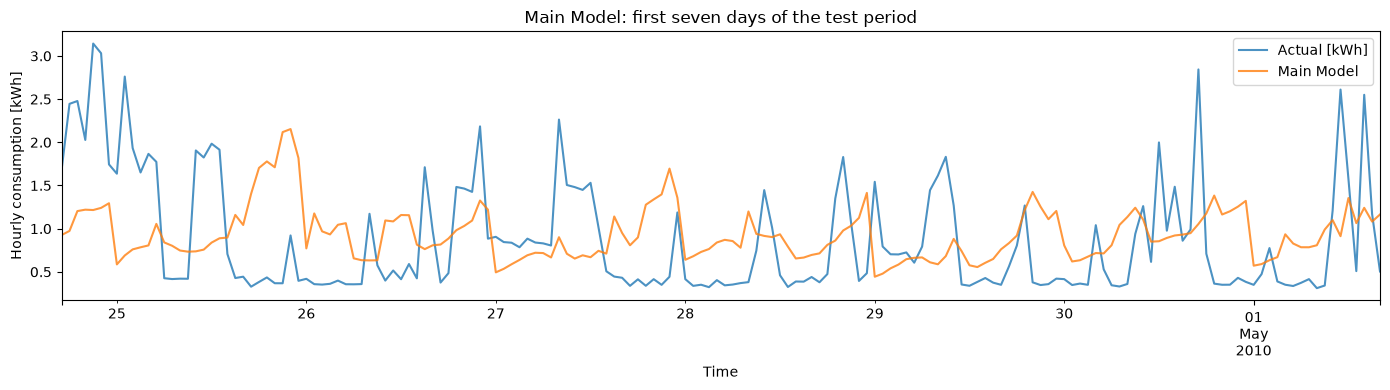

In [30]:
# Show the first seven calendar days, retaining gaps for excluded hours.
plot_start = main_test_predictions.time.min()
plot_end = plot_start + pd.Timedelta(days=7)
plot_data = main_test_predictions.set_index("time").loc[
    lambda frame: frame.index < plot_end, ["Actual [kWh]", "Main Model"]
].reindex(pd.date_range(plot_start, plot_end, freq="h", inclusive="left"))
ax = plot_data.plot(figsize=(14, 4), alpha=0.8)
ax.set(xlabel="Time", ylabel="Hourly consumption [kWh]",
       title="Main Model: first seven days of the test period")
plt.tight_layout()
plt.show()


### 8.3. Error analysis


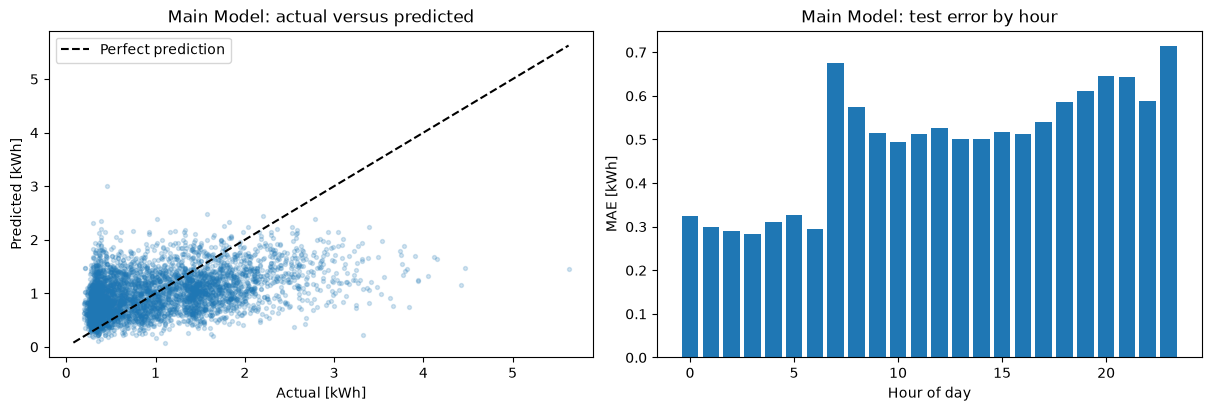

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].scatter(main_test_predictions["Actual [kWh]"],
                main_test_predictions["Main Model"], alpha=.2, s=8)
limits = [min(y_test.min(), pred_test_main.min()),
          max(y_test.max(), pred_test_main.max())]
axes[0].plot(limits, limits, "k--", label="Perfect prediction")
axes[0].set(xlabel="Actual [kWh]", ylabel="Predicted [kWh]",
            title="Main Model: actual versus predicted")
axes[0].legend()
error_by_hour = main_test_predictions.groupby(
    main_test_predictions.time.dt.hour
)["Absolute error [kWh]"].mean().reindex(range(24))
axes[1].bar(error_by_hour.index, error_by_hour.values)
axes[1].set(xlabel="Hour of day", ylabel="MAE [kWh]",
            title="Main Model: test error by hour")
plt.show()


Model predicts most common values and is not approaching the perfect predction. For lower cosumtion the model often overestimates, and for higher values - underestimates.

Test error per hour shows that the model has lower error from midnight to 6 am, with error peaks in morning and evening hours. 

## 9. Test evaluation comparison across models

In [32]:
z_test_reduced = pd.DataFrame(
    scaler_reduced.transform(test[FEATURES_REDUCED]),
    columns=FEATURES_REDUCED,
    index=test.index,
)
test_predictions = {
    "Main Model": pred_test_main,
    "Reduced Model": model_reduced.predict(z_test_reduced),
    "Mean baseline": dummy_mean.predict(z_test_main),
    "24-hour persistence": test[lag].to_numpy(),
}
test_comparison = pd.DataFrame.from_dict(
    {name: scores(y_test, prediction)
     for name, prediction in test_predictions.items()},
    orient="index",
).rename_axis("Method")
print("Shared test hours:", len(test))
display(test_comparison)

# Keep actual values and predictions aligned for later inspection.
test_predictions_df = pd.DataFrame(
    {"time": test["time"], "Actual [kWh]": y_test, **test_predictions},
    index=test.index,
)

# Verify that test transformation left the fitted scalers unchanged.
for scaler, snapshot in [(scaler_reduced, scaler_reduced_snapshot),
                         (scaler_main, scaler_main_snapshot)]:
    np.testing.assert_array_equal(scaler.mean_, snapshot[0])
    np.testing.assert_array_equal(scaler.scale_, snapshot[1])
    assert int(scaler.n_samples_seen_) == snapshot[2]


Shared test hours: 4931


,MAE [kWh],RMSE [kWh]
Method,,
Main Model,0.491053,0.635894
Reduced Model,0.541024,0.683901
Mean baseline,0.616760,0.725038
24-hour persistence,0.513124,0.763739


Main model has lowest errors on test dataset as well. Other models have lower errors on test then on validation, meaning that the reduction of error may be connected to the specifics of chronological data split

### 9.1. Relative error reduction


In [33]:
reference_scores = test_comparison.drop(index="Main Model")
relative_improvement = (
    (reference_scores - test_comparison.loc["Main Model"])
    .div(reference_scores) * 100
).rename(columns={
    "MAE [kWh]": "MAE reduction [%]",
    "RMSE [kWh]": "RMSE reduction [%]",
})
relative_improvement.index.name = "Reference method"
display(relative_improvement)


,MAE reduction [%],RMSE reduction [%]
Reference method,,
Reduced Model,9.236438,7.019632
Mean baseline,20.381805,12.295031
24-hour persistence,4.301227,16.739348


Positive percentages indicate lower error for the Main Model than for the reference. 

The Main Model improves upon the 24-hour persistence baseline by 4.30% in MAE and 16.74% in RMSE.

The relatively small MAE reduction shows that the improvement in average prediction accuracy is slight. However, larger RMSE reduction shows that the Main Model is more effective at reducing large prediction errors.

## 10. Summary


**Model performance:**
The Main Model achieved the best results (MAE = 0.603, RMSE = 0.778 kWh on the validation, MAE = 0.491 kWh, RMSE = 0.636 kWh on the test).

**Baseline comparison:** 
Compared to 24-hour persistence, the Main Model reduced MAE by 4.30% and RMSE by 16.74%, with a slight improvement in average accuracy but better handling of large errors.

**Error analysis:**
Predictions are more accurate during nighttime. The model tends to overestimate low consumption and underestimate consumption peaks.

**Limitations:**
The dataset contains only one household, and the model may not generalize to other households. Real-world forecasting would also require weather forecasts instead of actual future temperatures.

**Future improvements:**
nonlinear models, cyclic encoding of time features, usage of temperature forecast data instead of actual temperature, and evaluation on additional households or time periods.